# Prototype with interactions

**Data source:** none (layout only). Base images: the approved low-fidelity prototype of Part 4 (`lowfi_main_screen.png`, `lowfi_detail_screen.png`).
**Date:** 2026-11-05
**Authors:** Group 3, Presentation and Visualization (Infovis2627)
**Description:** Part 5, task 5.3. The approved wireframes are completed with the planned interactions: each one is marked with its number (I1 to I9, see `interaction_plan.ipynb`) at the place where it happens, and the new controls (sort toggle, month rule, tooltip, selected bar) are drawn in.

---

## Contents

1. [Data loading](#1.-Data-loading)
2. [Initial exploration](#2.-Initial-exploration)
3. [Cleaning and preparation](#3.-Cleaning-and-preparation)
4. [Analysis: where each interaction goes](#4.-Analysis:-where-each-interaction-goes)
5. [Accessible visualisation: annotated wireframes](#5.-Accessible-visualisation:-annotated-wireframes)
6. [Export](#6.-Export)
7. [Conclusions](#Conclusions)

In [1]:
# ── Imports ──────────────────────────────────────────────────────────────────
import sys
from pathlib import Path

import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image

PART4_IMAGES = Path('../../Part 4 - Chart Selection and Encoding/images')
IMAGES_DIR = Path('../images')
OUTPUT_DIR = Path('prototype_interactions_output')
IMAGES_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)

INK, MARK = '#1A1A1A', '#0066CC'     # marks in the focus blue, numbers in white (contrast 5.6:1)
plt.rcParams.update({'font.family': 'DejaVu Sans'})
print('Python', sys.version.split()[0], '| matplotlib', matplotlib.__version__)

Python 3.13.18 | matplotlib 3.11.2


## 1. Data loading

In [2]:
# ── Load the approved wireframes (images, in pixels) ─────────────────────────
# The top 60 px hold the Part 4 figure title, which is replaced by a new title here
TITLE_STRIP = 60
main_wireframe = Image.open(PART4_IMAGES / 'lowfi_main_screen.png').convert('RGB')
detail_wireframe = Image.open(PART4_IMAGES / 'lowfi_detail_screen.png').convert('RGB')
main_wireframe = main_wireframe.crop((0, TITLE_STRIP, main_wireframe.width, main_wireframe.height))
detail_wireframe = detail_wireframe.crop((0, TITLE_STRIP, detail_wireframe.width, detail_wireframe.height))
print('Main:', main_wireframe.size, '| Detail:', detail_wireframe.size)

Main: (1260, 797) | Detail: (1260, 797)


## 2. Initial exploration

The interactions come from `interaction_plan.csv` (task 5.1).

## 3. Cleaning and preparation

Not applicable.

## 4. Analysis: where each interaction goes

In [3]:
# ── Position of each mark, in pixels of the full wireframe images (the title strip is subtracted when drawing) ─
plan = pd.read_csv('interaction_plan_output/interaction_plan.csv')
names = dict(zip(plan['id'], plan['name']))

MAIN_MARKS = {'I1': (1222, 228), 'I2': (1170, 290), 'I3': (858, 115), 'I4': (1130, 395),
              'I5': (560, 300), 'I6': (705, 330)}
DETAIL_MARKS = {'I1': (1222, 228), 'I2': (1170, 290), 'I3': (830, 115), 'I4': (1130, 395),
                'I6': (300, 330), 'I7': (1105, 510), 'I8': (930, 762), 'I9': (505, 708)}
print(f'{len(MAIN_MARKS)} marks on the main screen, {len(DETAIL_MARKS)} on the detail screen; '
      f'all 9 interactions placed: {set(MAIN_MARKS) | set(DETAIL_MARKS) == set(names)}')

6 marks on the main screen, 8 on the detail screen; all 9 interactions placed: True


## 5. Accessible visualisation: annotated wireframes

Each interaction is a numbered circle (white number on the focus blue, contrast 5.6:1) and a legend under the wireframe repeats the numbers with their names, so the figure does not depend on colour.

In [4]:
# ── Drawing helpers ───────────────────────────────────────────────────────────

def number_mark(ax, xy, label):
    xy = (xy[0], xy[1] - TITLE_STRIP)
    ax.add_patch(plt.Circle(xy, 17, facecolor=MARK, edgecolor='white', linewidth=1.5, zorder=5))
    ax.text(xy[0], xy[1], label, ha='center', va='center', fontsize=6, color='white', weight='bold', zorder=6)


def annotated(image, marks, extra, legend_ids, title, file_name):
    width, height = image.size
    total = height + 120 + 50                       # 50 px for the title above, 120 px for the legend below
    fig = plt.figure(figsize=(6.3, 6.3 * total / width))
    ax = fig.add_axes([0, 120 / total, 1, height / total])
    ax.imshow(image)
    ax.set_xlim(0, width)
    ax.set_ylim(height, 0)
    ax.axis('off')
    extra(ax)
    for label, xy in marks.items():
        number_mark(ax, xy, label)
    legend = '   '.join(f'{i} {names[i]}' for i in legend_ids)
    fig.text(0.01, 60 / total, 'Interactions: ' + legend, fontsize=6.5, color=INK, wrap=True, va='center')
    fig.text(0.01, 1 - 12 / total, title, fontsize=10, color=INK, va='top')
    fig.savefig(IMAGES_DIR / file_name, dpi=200)
    return fig


def main_extra(ax):
    # I5: the same month marked by a rule in C1, C2 and C3
    t = TITLE_STRIP
    for x, top, bottom in [(560, 290, 510), (277, 590, 755), (752, 590, 755)]:
        ax.plot([x, x], [top - t, bottom - t], color=MARK, linestyle='--', linewidth=1.2)
    # I6: tooltip box next to the rule
    ax.add_patch(plt.Rectangle((575, 345 - t), 230, 52, facecolor='white', edgecolor=INK, linewidth=0.8))
    ax.text(585, 371 - t, 'Aug 2016 - City Hotel\nGuests: 4,200 (example)', fontsize=5.5, va='center', color=INK)


def detail_extra(ax):
    # I7: the selected bar (first bar of the City panel) gets an outline
    t = TITLE_STRIP
    ax.add_patch(plt.Rectangle((103, 312 - t), 142, 34, facecolor='none', edgecolor=MARK, linewidth=2))
    # I9: sort toggle under the bars
    ax.add_patch(plt.Rectangle((40, 697 - t), 450, 26, facecolor='white', edgecolor=INK, linewidth=0.8))
    ax.text(50, 710 - t, 'Sort: (o) By guests   ( ) Alphabetical', fontsize=5.5, va='center', color=INK)
    # I6: tooltip on the selected bar
    ax.add_patch(plt.Rectangle((250, 340 - t), 200, 46, facecolor='white', edgecolor=INK, linewidth=0.8))
    ax.text(258, 363 - t, 'Portugal - City Hotel\nGuests: value (example)', fontsize=5.5, va='center', color=INK)


print('Helpers ready')

Helpers ready


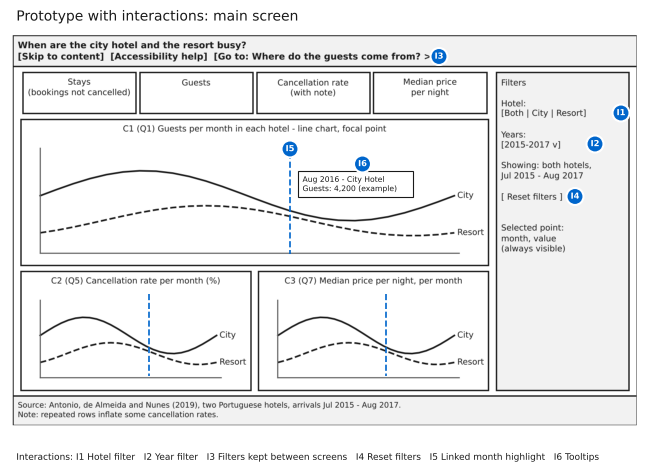

In [5]:
# ── Main screen with interactions ─────────────────────────────────────────────
annotated(main_wireframe, MAIN_MARKS, main_extra, ['I1', 'I2', 'I3', 'I4', 'I5', 'I6'],
          'Prototype with interactions: main screen', 'prototype_main_interactions.png')
plt.show()

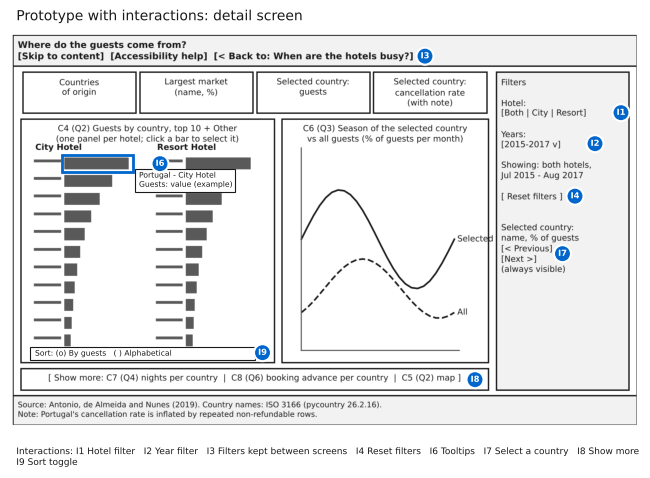

In [6]:
# ── Detail screen with interactions ───────────────────────────────────────────
annotated(detail_wireframe, DETAIL_MARKS, detail_extra, ['I1', 'I2', 'I3', 'I4', 'I6', 'I7', 'I8', 'I9'],
          'Prototype with interactions: detail screen', 'prototype_detail_interactions.png')
plt.show()

## 6. Export

In [7]:
# ── Export: positions of the marks ────────────────────────────────────────────
marks = pd.DataFrame([(screen, i, x, y) for screen, d in [('main', MAIN_MARKS), ('detail', DETAIL_MARKS)]
                      for i, (x, y) in d.items()], columns=['screen', 'interaction', 'x_px', 'y_px'])
marks.to_csv(OUTPUT_DIR / 'interaction_marks.csv', index=False)
marks

,screen,interaction,x_px,y_px
0,main,I1,1222,228
1,main,I2,1170,290
2,main,I3,858,115
3,main,I4,1130,395
4,main,I5,560,300
5,main,I6,705,330
6,detail,I1,1222,228
7,detail,I2,1170,290
8,detail,I3,830,115
9,detail,I4,1130,395


## Conclusions

The approved layout needs only small additions for the interactions: a sort toggle under the country bars, the month rule and tooltips. The filters, reset, links between screens, "Show more" and the Previous / Next buttons were already in the Part 4 prototype.